 Klasyfikacja wydźwięku PolEmo: przydatność zbioru do automatycznego przetwarzania

**Cel:** sprawdzić, czy etykiety całych tekstów (`plus_m`, `minus_m`, `zero`, `amb`) da się rozpoznawać automatycznie prostymi klasyfikatorami (regresja logistyczna, bez dostrajania transformerów) oraz jak na wynik wpływają reprezentacja tekstu i lematyzacja.

**Dane:** `all.text.train.txt` (6573 teksty) do treningu, `all.text.test.txt` (820 tekstów) jako wydzielony zbiór testowy. Podział jest stratyfikowany (rozkład klas w obu zbiorach jest zbliżony, patrz 1.2). Zbioru dev nie używamy, więc hiperparametry są stałe i nie są strojone.

**Reprezentacje**

| Reprezentacja | Model | Formy | Lematy |
|---|---|---|---|
| TF-IDF (1-2-gramy) | - | ✓ | ✓ |
| Word2Vec, średnia wektorów | IPI PAN `nkjp+wiki-forms-all-100-skipg-ns` (uczony na **formach**) | ✓ | ✓ |
| Word2Vec, średnia wektorów | IPI PAN `nkjp+wiki-lemmas-all-100-skipg-ns` (uczony na **lematach**) | | ✓ |
| fastText, średnia wektorów | `clarin-pl/fastText-kgr10` (skipgram, dim 100, n-gramy znakowe) | ✓ | ✓ |
| Enkoder zdań | `sdadas/mmlw-roberta-base` | ✓ | |

Lematyzacja: spaCy `pl_core_news_lg`.

**Ewaluacja:** accuracy i macro-F1 na zbiorze testowym, macierze pomyłek oraz dodatkowo 5-krotna stratyfikowana walidacja krzyżowa na train (średnia ± odchylenie). Predykcje out-of-fold z walidacji krzyżowej służą do analizy tekstów anotowanych w Części I, które leżą w zbiorze treningowym.

Modele i cache osadzeń leżą w `../data/models` i `../data/cache` (poza repo). Pierwsze uruchomienie trwa kilkanaście minut (wczytanie modeli, lematyzacja, kodowanie na GPU), kolejne kilka minut.

# 0. Konfiguracja

In [2]:
import json
import pickle
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 220)

DATA = Path("../data/dataset_conll")
MODELS = Path("../data/models")
CACHE = Path("../data/cache")
ANNOT = Path("../annotation")
CACHE.mkdir(parents=True, exist_ok=True)

LABELS = ["plus_m", "minus_m", "zero", "amb"]
LABEL_COLORS = dict(zip(LABELS, ["#2e7d32", "#c62828", "#757575", "#f9a825"]))
COLS = {"raw": "formy", "lemmas": "lematy"}
SEED = 42
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
WORD = re.compile(r"\w")  # token z co najmniej jedną literą/cyfrą (bez samej interpunkcji)


def cached(name: str, compute):
    """Wynik obliczenia trzymany w ../data/cache, liczony tylko przy pierwszym uruchomieniu."""
    path = CACHE / f"{name}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    t = time.time()
    out = compute()
    path.write_bytes(pickle.dumps(out))
    print(f"{name}: policzone w {time.time() - t:.0f} s")
    return out

# 1. Dane

## 1.1 Wczytanie

Format fastText: jedna linia = jeden tekst, `__label__meta_*` na końcu. Tekst jest tokenizowany spacjami. Wersja `raw` (tokeny po spacji) idzie do TF-IDF, modeli statycznych i lematyzatora, a wersja `text` (po detokenizacji, jak w Części I) do enkodera zdań. `id` to numer linii, zgodny z `id` w anotacji z Części I.

In [3]:
def detokenize(text: str) -> str:
    text = re.sub(r" ([.,!?;:)%])", r"\1", text)
    return re.sub(r"\( ", "(", text)


def parse(line: str) -> dict:
    raw, label = line.rsplit(" __label__", 1)
    return {
        "raw": raw.strip(),
        "text": detokenize(raw.strip()),
        "label": label.strip().removeprefix("meta_"),
    }


def load(split: str) -> pd.DataFrame:
    path = DATA / f"all.text.{split}.txt"
    lines = [l for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]
    df = pd.DataFrame([{"id": i, **parse(l)} for i, l in enumerate(lines)])
    df["slowa"] = df["raw"].str.split().str.len()
    return df


train, test = load("train"), load("test")
assert len(train) == 6573 and len(test) == 820
y_train, y_test = train["label"].to_numpy(), test["label"].to_numpy()
train.head(3)

,id,raw,text,label,slowa
0,0,"Na samym wejściu hotel śmierdzi . W pokojach jest pleśń na ścianach , brudny dywan . W łazience śmierdzi chemią , hotel nie grzeje w pokojach panuje chłód . Wyposażenie pokoju jest stare , kran się rusza , drzwi na b...","Na samym wejściu hotel śmierdzi. W pokojach jest pleśń na ścianach, brudny dywan. W łazience śmierdzi chemią, hotel nie grzeje w pokojach panuje chłód. Wyposażenie pokoju jest stare, kran się rusza, drzwi na balkon n...",minus_m,60
1,1,"Ze swoimi dziećmi ( 10 lat i 2 latka ) chodzę właściwie tylko do doktor . Uważam , że jest świetnym specjalistą , nie traktuje pacjenta "" z góry "" , jest miła , rzeczowa i doskonale pamięta oraz zna swoich małych pac...","Ze swoimi dziećmi (10 lat i 2 latka) chodzę właściwie tylko do doktor. Uważam, że jest świetnym specjalistą, nie traktuje pacjenta "" z góry "", jest miła, rzeczowa i doskonale pamięta oraz zna swoich małych pacjentów....",plus_m,116
2,2,"Chciał em zestaw do podstawowych prac coś przykręcić coś odkręcić - jako , ze nie jestem wielkim majsterkowiczem nie wymagał em wiele jednak sam zestaw jest bardzo mały - wielkości połowy kartki A4 zarówno grzechotka...","Chciał em zestaw do podstawowych prac coś przykręcić coś odkręcić - jako, ze nie jestem wielkim majsterkowiczem nie wymagał em wiele jednak sam zestaw jest bardzo mały - wielkości połowy kartki A4 zarówno grzechotka ...",minus_m,117


## 1.2 Rozkład klas i długość tekstów

liczba      udział [%]      
         train test      train  test
label                               
plus_m    1824  227       27.7  27.7
minus_m   2469  339       37.6  41.3
zero       971  118       14.8  14.4
amb       1309  136       19.9  16.6

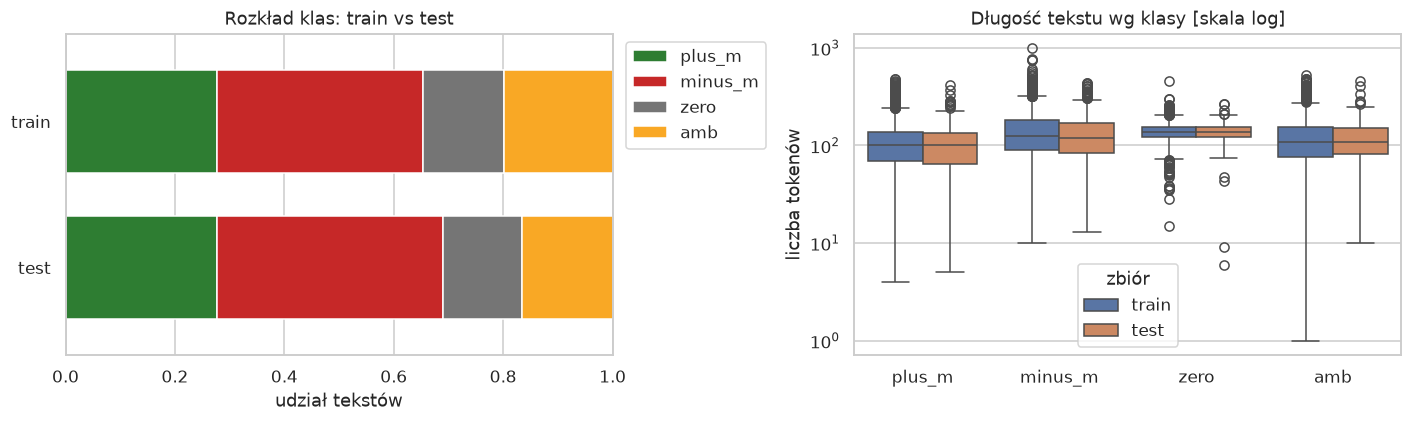

mean    50%    max
zbiór label                       
test  amb      126.0  108.0  455.0
      minus_m  138.0  119.0  440.0
      plus_m   111.0  100.0  413.0
      zero     139.0  138.0  265.0
train amb      127.0  109.0  531.0
      minus_m  148.0  124.0  987.0
      plus_m   115.0  102.0  480.0
      zero     139.0  136.0  452.0

In [4]:
dist = pd.DataFrame(
    {"train": train["label"].value_counts(), "test": test["label"].value_counts()}
).reindex(LABELS)
share = dist / dist.sum()
display(pd.concat({"liczba": dist, "udział [%]": (share * 100).round(1)}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
share.T.plot.barh(
    stacked=True, color=[LABEL_COLORS[l] for l in LABELS], ax=axes[0], width=0.7
)
axes[0].set_xlim(0, 1)
axes[0].invert_yaxis()
axes[0].set_xlabel("udział tekstów")
axes[0].set_title("Rozkład klas: train vs test")
axes[0].legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")

both = pd.concat([train.assign(zbiór="train"), test.assign(zbiór="test")])
sns.boxplot(data=both, x="label", y="slowa", hue="zbiór", order=LABELS, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_xlabel("")
axes[1].set_ylabel("liczba tokenów")
axes[1].set_title("Długość tekstu wg klasy [skala log]")
plt.tight_layout()
plt.show()
display(both.groupby(["zbiór", "label"])["slowa"].describe()[["mean", "50%", "max"]].round(0))

# 2. Lematyzacja (spaCy `pl_core_news_lg`)

Tekst jest już tokenizowany, więc do spaCy podajemy gotowe tokeny (`Doc(words=...)`), a nie surowy napis. Dzięki temu wersja z lematami ma dokładnie te same tokeny co wersja z formami, a różni je tylko lematyzacja. Parser i NER są wyłączone, bo lematyzator potrzebuje tylko `morphologizer` i `tagger`.

In [5]:
import spacy
from spacy.tokens import Doc


def lemmatize(texts) -> list[str]:
    nlp = spacy.load("pl_core_news_lg", disable=["parser", "ner"])
    docs = nlp.pipe((Doc(nlp.vocab, words=t.split()) for t in texts), batch_size=64)
    return [" ".join((t.lemma_ or t.text).replace(" ", "_") for t in d) for d in docs]


for name, df in [("train", train), ("test", test)]:
    df["lemmas"] = cached(f"lemmas_{name}", lambda: lemmatize(df["raw"]))
    assert (df["raw"].str.split().str.len() == df["lemmas"].str.split().str.len()).all()

ex = train.iloc[0]
pd.DataFrame({"forma": ex["raw"].split()[:30], "lemat": ex["lemmas"].split()[:30]}).T

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
forma,Na,samym,wejściu,hotel,śmierdzi,.,W,pokojach,jest,pleśń,...,",",hotel,nie,grzeje,w,pokojach,panuje,chłód,.,Wyposażenie
lemat,na,sam,wejść,hotel,śmierdzić,.,w,pokoj,być,pleśń,...,",",hotel,nie,grzać,w,pokój,panować,chłód,.,wyposażenie


## 2.1 Rozmiar słownika: formy vs lematy

In [6]:
def vocab_stats(texts) -> dict:
    counts = Counter(w.lower() for t in texts for w in t.split() if WORD.search(w))
    c = pd.Series(counts)
    return {
        "tokeny": int(c.sum()),
        "typy": len(c),
        "typy (min. 2 wystąpienia)": int((c >= 2).sum()),
        "hapax legomena": int((c == 1).sum()),
    }


VOCAB = pd.DataFrame({COLS[c]: vocab_stats(train[c]) for c in COLS}).T
VOCAB["TTR"] = VOCAB["typy"] / VOCAB["tokeny"]
VOCAB.loc["redukcja [%]"] = (1 - VOCAB.loc["lematy"] / VOCAB.loc["formy"]) * 100
display(VOCAB.round(3))

pairs = pd.DataFrame(
    {
        "forma": [w.lower() for t in train["raw"] for w in t.split()],
        "lemat": [w.lower() for t in train["lemmas"] for w in t.split()],
    }
)
pairs = pairs[pairs["forma"].str.contains(r"\w")]
forms = pairs.groupby("lemat")["forma"].agg(lambda s: sorted(set(s)))
top = forms[forms.str.len().sort_values(ascending=False).index[:12]]
display(
    top.map(lambda f: f"{len(f)} form: " + ", ".join(f[:12])).to_frame(
        "lematy z największą liczbą form w korpusie"
    )
)

,tokeny,typy,typy (min. 2 wystąpienia),hapax legomena,TTR
formy,734727.0,73200.000,33428.000,39772.000,0.100
lematy,734729.0,45894.000,20276.000,25618.000,0.062
redukcja [%],-0.0,37.303,39.344,35.588,37.303


,lematy z największą liczbą form w korpusie
lemat,
podać,"29 form: poda, podaj, podają, podając, podająca, podający, podającą, podali, podam, podamy, podana, podane"
prowadzić,"28 form: prowadzenia, prowadzenie, prowadzeniem, prowadzeniu, prowadzi, prowadzili, prowadzimy, prowadzić, prowadził, prowadziła, prowadziło, prowadziły"
wykonywać,"26 form: wykonuje, wykonują, wykonując, wykonującego, wykonujących, wykonuję, wykonywali, wykonywana, wykonywane, wykonywanego, wykonywanej, wykonywania"
być,"25 form: byc, bycia, bycie, byli, być, był, była, było, były, bądź, będzie, będziecie"
dobry,"25 form: dobra, dobre, dobrego, dobrej, dobremu, dobry, dobrych, dobrym, dobrymi, dobrzy, dobrą, lepsza"
stosować,"24 form: stosowali, stosowana, stosowane, stosowanego, stosowania, stosowanie, stosowaniem, stosowaniu, stosowano, stosowany, stosowanych, stosowanym"
duży,"24 form: duża, duże, dużego, dużej, dużemu, duży, dużych, dużym, dużymi, dużą, największa, największe"
zajmować,"23 form: zajmowali, zajmowane, zajmowanego, zajmowania, zajmowanie, zajmowaniu, zajmowano, zajmowany, zajmowanych, zajmować, zajmował, zajmowała"
oceniać,"23 form: ocenia, oceniają, oceniając, oceniająca, oceniające, oceniających, oceniam, oceniamy, oceniana, oceniane, oceniani, oceniania"


In [7]:
m = [(f, l) for t, u in zip(train["raw"], train["lemmas"])
     for f, l in zip(t.split(), u.split())
     if not WORD.search(f) and WORD.search(l)]
print(m)

[('€', '€oty'), ('€', '€oty')]


# 3. Reprezentacje tekstu

## 3.1 TF-IDF

`TfidfVectorizer` na tokenach po spacji (z interpunkcją, bo np. „!” niesie informację o wydźwięku), małe litery, uni- i bigramy, `min_df=2`, `sublinear_tf`. Wektoryzator jest częścią potoku, więc w walidacji krzyżowej słownik buduje się tylko na foldach treningowych.

In [13]:
def tfidf() -> TfidfVectorizer:
    return TfidfVectorizer(
        tokenizer=str.split,
        token_pattern=None, # domyślnie tokenizer wywala pojedyncze znaki - jednak np. "!" jest istotne - zmieniamy pattern na none, mamy własny tokenizer
        lowercase=True,
        ngram_range=(1, 2), # tu chodzi o tokeny (bigramy) będące kolejnymi słowami (np. nie polecam)
        min_df=2, # cecha zostaje tylko jak występuje w co najmniej 2 dokumentach (tekstach)    
        sublinear_tf=True, # 1 + ln(tf) -> slowo wystepujace 10x ma 3.3x wage a nie 10x
    )


TFIDF_DIM = {}
for c in COLS: # COLS = {"raw": "formy", "lemmas": "lematy"}
    v = tfidf().fit(train[c])
    uni = sum(" " not in f for f in v.get_feature_names_out()) # unigramy są bez spacji
    TFIDF_DIM[COLS[c]] = {"cechy (1-2-gramy)": len(v.vocabulary_), "unigramy": uni}
display(pd.DataFrame(TFIDF_DIM).T)

,cechy (1-2-gramy),unigramy
formy,112896,32175
lematy,97790,19227


## 3.2 Modele statyczne: Word2Vec (IPI PAN) i fastText (kgr10)

To działa tak:
1. każde słowo dostaje gęsty wektor (tutaj 100 liczb) - zamek (wawel) i zamek (w spodniach) dostają ten sam - dlatego statyczne
2. wektor na cały tekst to jest średnia tych wektorów


Wektor tekstu to średnia wektorów jego tokenów (pomijamy tokeny bez liter i cyfr). Najpierw szukamy tokenu w oryginalnej pisowni, a potem małymi literami.
- **Word2Vec:** token spoza słownika (OOV) jest pomijany. Jeśli cały tekst to OOV, dostaje wektor zerowy.
- Lematy wielowyrazowe ze spaCy (np. „np.” → `na_przykład`, „musiałem” → `musieć_być`) rozbijamy na słowa i każde wyszukujemy osobno.
- **fastText:** token OOV i tak dostaje wektor złożony z n-gramów znakowych. Liczymy go jako OOV tylko w statystyce.

Uwaga do pkt 2c: model `forms` był uczony na formach, a `lemmas` na lematach (lematyzacja IPI PAN). Konfiguracja „W2V forms | lematy” pokazuje, co dzieje się, gdy lematy trafiają do modelu uczonego na formach.

In [ ]:
from gensim.models import KeyedVectors
from gensim.models.fasttext import load_facebook_vectors

STATIC_FILES = {
    "w2v_forms": lambda: KeyedVectors.load_word2vec_format(MODELS / "w2v_forms.txt.gz"),
    "w2v_lemmas": lambda: KeyedVectors.load_word2vec_format(MODELS / "w2v_lemmas.txt.gz"),
    "fasttext": lambda: load_facebook_vectors(
        str(MODELS / "kgr10.plain.skipgram.dim100.neg10.bin") # token dostaje wektor z n-gramów znakowych (np. "kot" -> "ko", "kot", "ot") - pozwala to na reprezentację słów nieznanych w modelu, np. "koty" czy "kotek"
    ),
}
_KV = {} # cache, model wczytuje się raz


def get_kv(model: str):
    if model not in _KV:
        t = time.time()
        _KV[model] = STATIC_FILES[model]()
        print(f"wczytano {model}: {len(_KV[model])} słów, {time.time() - t:.0f} s")
    return _KV[model]


def embed_static(texts, model: str) -> dict:
    kv = get_kv(model)
    subword = model == "fasttext" 
    X = np.zeros((len(texts), kv.vector_size), dtype=np.float32) # macierz wyników - wypełniona zerami - tekst bez żadnego słowa ze słownika zostaje wektorem 0
    oov, n_tok = Counter(), 0
    for i, t in enumerate(texts):
        vecs = []
        for w in t.replace("_", " ").split():  # lematy wielowyrazowe (np. na_przykład) po słowie
            if not WORD.search(w):
                continue
            n_tok += 1
            key = next((k for k in (w, w.lower()) if k in kv.key_to_index), None)
            if key is None:
                oov[w.lower()] += 1
                if not subword:
                    continue
                key = w.lower()  # fastText: wektor z n-gramów znakowych
            vecs.append(kv[key])
        if vecs:
            X[i] = np.mean(vecs, axis=0)
    return {"X": X, "oov": oov, "n_tok": n_tok} # {wektor, liczba oov, liczba tokenów}


STATIC = [  # (nazwa w tabelach, model, kolumna tekstu)
    ("W2V forms", "w2v_forms", "raw"),
    ("W2V forms", "w2v_forms", "lemmas"),
    ("W2V lemmas", "w2v_lemmas", "lemmas"),
    ("fastText", "fasttext", "raw"),
    ("fastText", "fasttext", "lemmas"),
]
EMB = {}
for label, model, col in STATIC:
    EMB[f"{label} | {COLS[col]}"] = {
        split: cached(f"emb_{model}_{col}_{split}", lambda: embed_static(df[col], model))
        for split, df in [("train", train), ("test", test)]
    }
_KV.clear()  # zwolnienie pamięci (fastText zajmuje kilka GB)

for name, e in EMB.items():
    assert e["train"]["X"].shape == (len(train), 100) and not np.isnan(e["train"]["X"]).any()

## 3.3 Pokrycie słownika (OOV)

In [ ]:
OOV = pd.DataFrame(
    {
        name: {
            "tokeny OOV [%]": 100 * sum(e["train"]["oov"].values()) / e["train"]["n_tok"],
            "typy OOV": len(e["train"]["oov"]),
            "teksty z wektorem zerowym": int((np.abs(e["train"]["X"]).sum(1) == 0).sum()),
            "najczęstsze OOV": ", ".join(
                f"{w} ({c})" for w, c in e["train"]["oov"].most_common(12)
            ),
        }
        for name, e in EMB.items()
    }
).T
display(OOV)


## co tu się stało -> na czuja model uczony na lematach powinien mieć lepsze OOV (mniejsze) na lematach, niż model uczony na formach
## słownik uczony na formach zawiera wszystkie formy (pokój, pokoje itp.) więc się nie rozwala
## prawie każdy lemat ze spaCy powinien mieć w nim swój wektor -> OOV tylko dla lematów zepsutych przez spaCy (np. pokoio)


## słownik uczony na lematach zawiera tylko lematy według lematyzatora IPI PAN
## jeśli spaCy zwróci coś co IPI PAN nie nazwał Lematem -> OOV



,tokeny OOV [%],typy OOV,teksty z wektorem zerowym,najczęstsze OOV
W2V forms | formy,0.990708,5143,0,"usg (307), pap (143), tv (127), bedzie (66), internetu (48), usa (45), max (44), musiałem (43), prl (27), booking.com (27), wc (26), and (24)"
W2V forms | lematy,2.391461,9893,0,"usg (307), pap (143), pokoio (135), tv (127), urządzć (112), gwiazdeka (110), jacuzz (93), niemić (70), bedzie (65), urozmaicyć (60), śmierdzić (53), usa (45)"
W2V lemmas | lematy,4.817418,17334,0,"pokoje (607), m (329), śniadania (229), tez (193), podobne (175), usg (158), zadbany (146), zwany (140), polecam (139), d (136), pokoio (135), urządzć (112)"
fastText | formy,0.457857,3057,0,"5.0 (19), hualuxe (13), 3.0 (10), 4.5 (10), humoruzy (7), 5.5 (6), mitsis (6), buuteeq (6), tuchendler (6), hotelstars (5), oleaceina (5), 4.0 (5)"
fastText | lematy,1.691502,7524,0,"pokoio (135), urządzć (112), gwiazdeka (110), niemić (70), urozmaicyć (60), przemić (43), kręgosłupo (43), podsumowuć (42), pokoej (40), mozeć (35), kolokwie (35), drinek (34)"


## 3.4 Enkoder zdań `sdadas/mmlw-roberta-base`

RoBERTa base - oparte na transformerze - reprezentacja znaczenia całych zdań i tekstów. Wektor słowa zależy od kontekstu - np. `nie polecam` i `polecam` to 2 różne wektory - bo model widzi kontekst.

Zgodnie z kartą modelu do tekstu dodajemy prefiks `"zapytanie: "` (MMLW używa go dla zapytań oraz w zadaniach klasyfikacji i klasteryzacji w PL-MTEB). Wektory są normalizowane. Model przyjmuje maksymalnie 512 tokenów, a dłuższe teksty są obcinane, więc sprawdzamy, jak często się to zdarza. Enkoder dostaje tekst po detokenizacji, bez lematyzacji.

In [11]:
import torch
from sentence_transformers import SentenceTransformer

MMLW = "sdadas/mmlw-roberta-base"


def embed_mmlw() -> dict:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = SentenceTransformer(MMLW, device=device)
    out = {"max_seq_length": model.max_seq_length}
    for split, df in [("train", train), ("test", test)]:
        texts = ("zapytanie: " + df["text"]).tolist()
        out[f"n_tok_{split}"] = np.array(
            [len(ids) for ids in model.tokenizer(texts)["input_ids"]]
        )
        out[split] = model.encode(
            texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True
        )
    return out


ST = cached("emb_mmlw", embed_mmlw)
EMB["mmlw-roberta | formy"] = {s: {"X": ST[s]} for s in ("train", "test")}
assert ST["train"].shape == (len(train), 768)

n_tok = np.concatenate([ST["n_tok_train"], ST["n_tok_test"]])
print(
    f"max_seq_length = {ST['max_seq_length']}; tokenów na tekst: mediana {np.median(n_tok):.0f}, "
    f"p95 {np.percentile(n_tok, 95):.0f}; obcięte teksty: {(n_tok > ST['max_seq_length']).mean():.1%}"
)


max_seq_length = 512; tokenów na tekst: mediana 148, p95 348; obcięte teksty: 1.0%


# 4. Klasyfikacja

Wszędzie ten sam klasyfikator: `LogisticRegression` z `class_weight="balanced"`. Wagi klas wybraliśmy dlatego, że główną miarą jest macro-F1, a klasy `zero` i `amb` są mniej liczne. Osadzenia przechodzą przez `StandardScaler`, a TF-IDF trafia do klasyfikatora bez skalowania. Punkt odniesienia to klasyfikator klasy większościowej.

Dla każdej konfiguracji:
1. 5-krotna stratyfikowana walidacja krzyżowa na train daje macro-F1 (średnia ± odchylenie) i predykcje out-of-fold.
2. Model uczony na całym train jest oceniany na test.

In [14]:
def logreg() -> LogisticRegression:
    return LogisticRegression(max_iter=5000, class_weight="balanced")


EXPS = {
    "Baseline (klasa większościowa)": (
        "baseline", "-",
        DummyClassifier(strategy="most_frequent"),
        np.zeros((len(train), 1)), np.zeros((len(test), 1)),
    ),
    **{
        f"TF-IDF | {COLS[c]}": (
            "TF-IDF", COLS[c],
            make_pipeline(tfidf(), logreg()),
            train[c].to_numpy(), test[c].to_numpy(),
        )
        for c in COLS
    },
    **{
        name: (
            name.split(" | ")[0], name.split(" | ")[1],
            make_pipeline(StandardScaler(), logreg()),
            e["train"]["X"], e["test"]["X"],
        )
        for name, e in EMB.items()
    },
}


def run(pipe, Xtr, Xte) -> dict:
    oof = np.empty(len(y_train), dtype=object)
    cv = []
    for tr, va in SKF.split(Xtr, y_train):
        m = clone(pipe).fit(Xtr[tr], y_train[tr])
        oof[va] = m.predict(Xtr[va])
        cv.append(f1_score(y_train[va], oof[va], average="macro"))
    model = clone(pipe).fit(Xtr, y_train)
    return {"pred": model.predict(Xte), "oof": oof, "cv": np.array(cv), "model": model}


RUNS = {}
for name, (_, _, pipe, Xtr, Xte) in EXPS.items():
    t = time.time()
    RUNS[name] = run(pipe, Xtr, Xte)
    print(f"{name:32s} {time.time() - t:5.1f} s")

Baseline (klasa większościowa)     0.1 s
TF-IDF | formy                    38.1 s
TF-IDF | lematy                   39.5 s
W2V forms | formy                  3.1 s
W2V forms | lematy                 2.7 s
W2V lemmas | lematy                3.1 s
fastText | formy                   4.5 s
fastText | lematy                  3.7 s
mmlw-roberta | formy             120.5 s


## 4.1 Wyniki na zbiorze testowym i w walidacji krzyżowej

In [11]:
def dim(name: str) -> int:
    rep, tekst, _, Xtr, _ = EXPS[name]
    return TFIDF_DIM[tekst]["cechy (1-2-gramy)"] if rep == "TF-IDF" else Xtr.shape[1]


rows = []
for name, r in RUNS.items():
    rep, tekst, *_ = EXPS[name]
    f1c = f1_score(y_test, r["pred"], labels=LABELS, average=None)
    rows.append(
        {
            "model": name,
            "reprezentacja": rep,
            "tekst": tekst,
            "wymiar": dim(name),
            "accuracy": accuracy_score(y_test, r["pred"]),
            "macro-F1": f1_score(y_test, r["pred"], average="macro"),
            "CV macro-F1": r["cv"].mean(),
            "CV odch.": r["cv"].std(),
            **{f"F1 {l}": v for l, v in zip(LABELS, f1c)},
        }
    )
RESULTS = pd.DataFrame(rows).set_index("model")
display(
    RESULTS.round(3).style.background_gradient(
        cmap="Greens", subset=["accuracy", "macro-F1", "CV macro-F1"]
    ).format(precision=3)
)

,reprezentacja,tekst,wymiar,accuracy,macro-F1,CV macro-F1,CV odch.,F1 plus_m,F1 minus_m,F1 zero,F1 amb
model,,,,,,,,,,,
Baseline (klasa większościowa),baseline,-,1,0.413,0.146,0.137,0.000,0.000,0.585,0.000,0.000
TF-IDF | formy,TF-IDF,formy,112896,0.801,0.794,0.812,0.006,0.817,0.841,0.974,0.545
TF-IDF | lematy,TF-IDF,lematy,97790,0.813,0.808,0.817,0.011,0.818,0.854,0.974,0.584
W2V forms | formy,W2V forms,formy,100,0.738,0.738,0.743,0.004,0.740,0.779,0.945,0.489
W2V forms | lematy,W2V forms,lematy,100,0.744,0.740,0.731,0.007,0.738,0.791,0.928,0.505
W2V lemmas | lematy,W2V lemmas,lematy,100,0.749,0.746,0.731,0.003,0.753,0.791,0.921,0.519
fastText | formy,fastText,formy,100,0.773,0.776,0.766,0.010,0.804,0.793,0.958,0.551
fastText | lematy,fastText,lematy,100,0.766,0.761,0.752,0.010,0.777,0.804,0.930,0.532
mmlw-roberta | formy,mmlw-roberta,formy,768,0.841,0.833,0.795,0.010,0.870,0.869,0.945,0.651


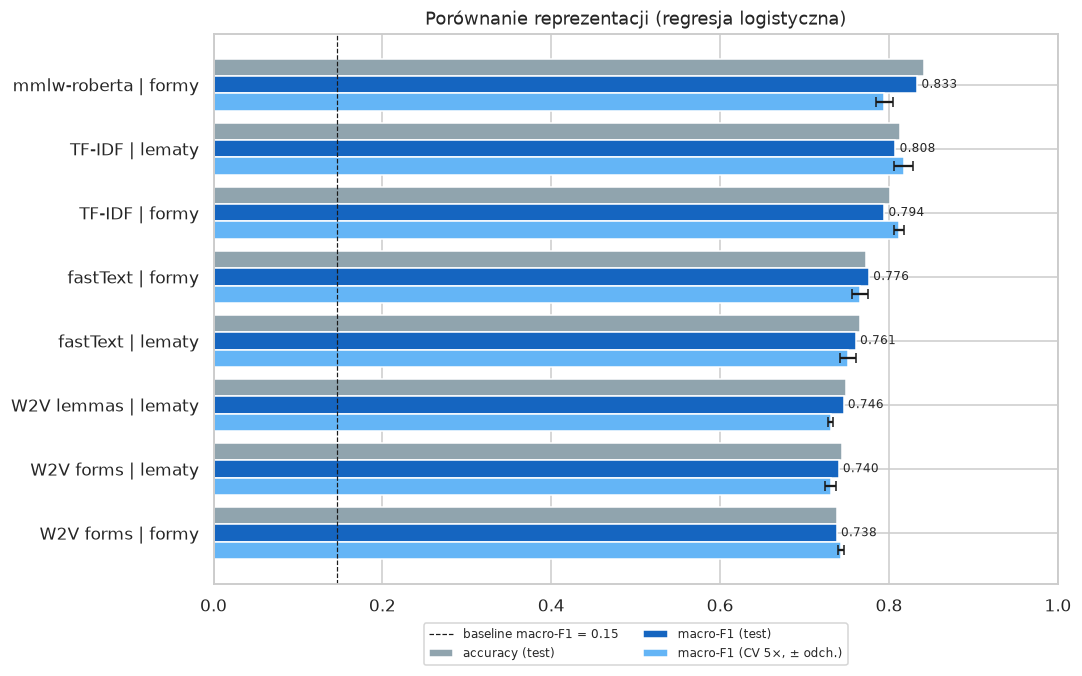

In [12]:
R = RESULTS.drop(index="Baseline (klasa większościowa)").sort_values("macro-F1")
MODELS_ORDER = list(R.index[::-1])  # od najlepszego na teście
y = np.arange(len(R))
h = 0.27
fig, ax = plt.subplots(figsize=(10, 0.6 * len(R) + 1.5))
ax.barh(y + h, R["accuracy"], h, label="accuracy (test)", color="#90a4ae")
ax.barh(y, R["macro-F1"], h, label="macro-F1 (test)", color="#1565c0")
ax.barh(
    y - h, R["CV macro-F1"], h, xerr=R["CV odch."], label="macro-F1 (CV 5×, ± odch.)",
    color="#64b5f6", capsize=3,
)
for yy, v in zip(y, R["macro-F1"]):
    ax.text(v + 0.005, yy, f"{v:.3f}", va="center", fontsize=8)
base = RESULTS.loc["Baseline (klasa większościowa)", "macro-F1"]
ax.axvline(base, color="k", ls="--", lw=0.8, label=f"baseline macro-F1 = {base:.2f}")
ax.set_yticks(y, R.index)
ax.set_xlim(0, 1)
ax.set_title("Porównanie reprezentacji (regresja logistyczna)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## 4.2 Czy różnice między modelami są istotne

Kolejność najlepszych modeli zależy od sposobu ewaluacji: na teście wygrywa enkoder zdań, a w walidacji krzyżowej TF-IDF. Dlatego dla kilku par modeli sprawdzamy:
- **test:** sparowany bootstrap (1000 losowań tekstów testowych ze zwracaniem) różnicy macro-F1 z 95% przedziałem,
- **CV:** różnicę macro-F1 fold po foldzie (wszystkie modele mają te same foldy, bo `SKF` ma stały `random_state`).

Dodatkowo podajemy F1 per klasa z predykcji out-of-fold na całym train (6573 teksty, czyli 8 razy więcej niż test).

In [13]:
def boot_diff(a: str, b: str, n: int = 1000) -> np.ndarray:
    rng = np.random.default_rng(SEED)
    pa, pb = RUNS[a]["pred"], RUNS[b]["pred"]
    out = []
    for _ in range(n):
        i = rng.integers(0, len(y_test), len(y_test))
        out.append(
            f1_score(y_test[i], pa[i], average="macro")
            - f1_score(y_test[i], pb[i], average="macro")
        )
    return np.array(out)


PAIRS = [
    ("mmlw-roberta | formy", "TF-IDF | lematy"),
    ("mmlw-roberta | formy", "TF-IDF | formy"),
    ("TF-IDF | lematy", "TF-IDF | formy"),
    ("fastText | formy", "W2V forms | formy"),
    ("fastText | lematy", "fastText | formy"),
    ("W2V lemmas | lematy", "W2V forms | formy"),
]
rows = []
for a, b in PAIRS:
    d = boot_diff(a, b)
    cv = RUNS[a]["cv"] - RUNS[b]["cv"]
    rows.append(
        {
            "A": a,
            "B": b,
            "Δ test (A−B)": RESULTS.loc[a, "macro-F1"] - RESULTS.loc[b, "macro-F1"],
            "95% CI test": f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]",
            "Δ CV (A−B)": cv.mean(),
            "A lepszy w foldach": f"{(cv > 0).sum()}/5",
        }
    )
display(pd.DataFrame(rows).round(3))

OOF_F1 = pd.DataFrame(
    {
        m: dict(
            zip(LABELS, f1_score(y_train, RUNS[m]["oof"], labels=LABELS, average=None)),
            **{"macro-F1": f1_score(y_train, RUNS[m]["oof"], average="macro")},
        )
        for m in MODELS_ORDER
    }
).T
display(OOF_F1.round(3).rename_axis("F1 out-of-fold (train)"))

,A,B,Δ test (A−B),95% CI test,Δ CV (A−B),A lepszy w foldach
0,mmlw-roberta | formy,TF-IDF | lematy,0.026,"[-0.002, +0.058]",-0.023,1/5
1,mmlw-roberta | formy,TF-IDF | formy,0.039,"[+0.009, +0.069]",-0.017,1/5
2,TF-IDF | lematy,TF-IDF | formy,0.013,"[-0.005, +0.031]",0.006,3/5
3,fastText | formy,W2V forms | formy,0.038,"[+0.015, +0.062]",0.023,5/5
4,fastText | lematy,fastText | formy,-0.016,"[-0.036, +0.006]",-0.014,1/5
5,W2V lemmas | lematy,W2V forms | formy,0.008,"[-0.019, +0.034]",-0.012,0/5


,plus_m,minus_m,zero,amb,macro-F1
F1 out-of-fold (train),,,,,
mmlw-roberta | formy,0.822,0.842,0.937,0.576,0.794
TF-IDF | lematy,0.817,0.856,0.969,0.628,0.817
TF-IDF | formy,0.816,0.846,0.971,0.614,0.812
fastText | formy,0.774,0.792,0.944,0.553,0.766
fastText | lematy,0.757,0.778,0.923,0.550,0.752
W2V lemmas | lematy,0.723,0.763,0.914,0.524,0.731
W2V forms | lematy,0.731,0.763,0.910,0.521,0.731
W2V forms | formy,0.745,0.773,0.925,0.529,0.743


## 4.3 Macierze pomyłek (zbiór testowy)

Kolor oznacza udział w wierszu (czułość dla klasy prawdziwej), a liczby w komórkach to liczba tekstów.

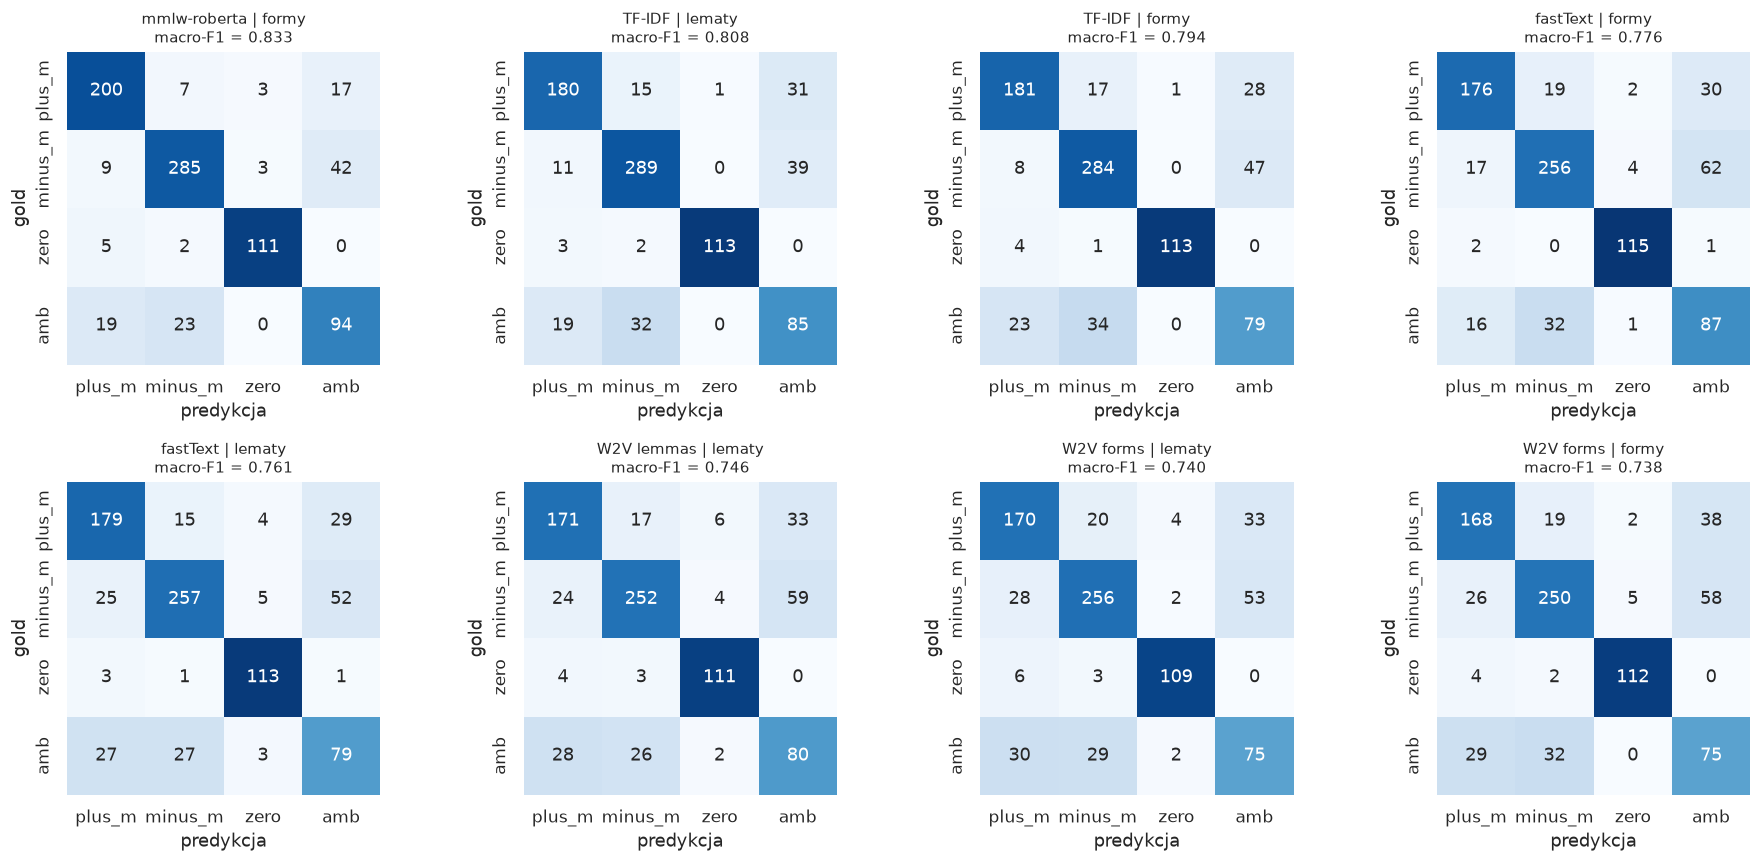

In [14]:
MODELS_MAIN = MODELS_ORDER
ncol = 4
nrow = int(np.ceil(len(MODELS_MAIN) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4 * nrow))
for ax, name in zip(axes.flat, MODELS_MAIN):
    cm = confusion_matrix(y_test, RUNS[name]["pred"], labels=LABELS)
    sns.heatmap(
        cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues",
        vmin=0, vmax=1, cbar=False, square=True,
        xticklabels=LABELS, yticklabels=LABELS, ax=ax,
    )
    ax.set_title(f"{name}\nmacro-F1 = {RESULTS.loc[name, 'macro-F1']:.3f}", fontsize=10)
    ax.set_xlabel("predykcja")
    ax.set_ylabel("gold")
for ax in axes.flat[len(MODELS_MAIN):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

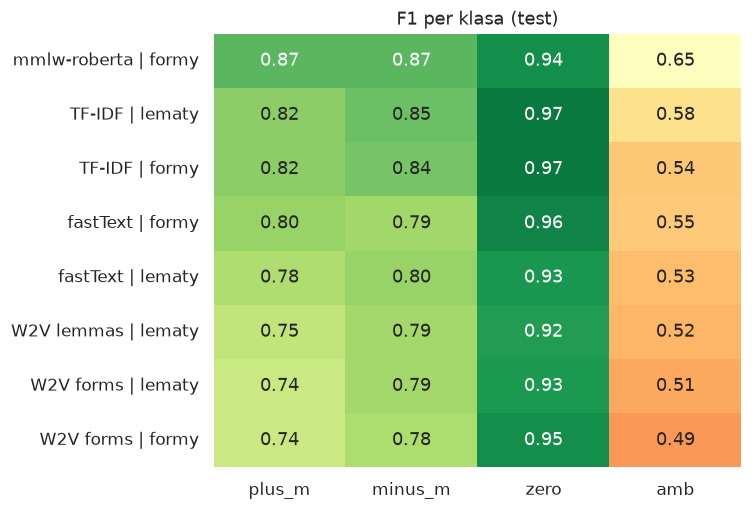

In [15]:
F1C = R[[f"F1 {l}" for l in LABELS]].iloc[::-1]
F1C.columns = LABELS
fig, ax = plt.subplots(figsize=(7, 0.45 * len(F1C) + 1.2))
sns.heatmap(F1C, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.3, vmax=1, ax=ax, cbar=False)
ax.set_title("F1 per klasa (test)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# 5. Lematyzacja: formy vs lematy

,słownik/OOV: formy,słownik/OOV: lematy,macro-F1 formy,macro-F1 lematy,Δ test,CV formy,CV lematy,Δ CV
porównanie,,,,,,,,
TF-IDF,112896 cech,97790 cech,0.794,0.808,0.013,0.812,0.817,0.006
W2V forms (ten sam model),OOV 1.0%,OOV 2.4%,0.738,0.740,0.002,0.743,0.731,-0.012
W2V forms → W2V lemmas,OOV 1.0%,OOV 4.8%,0.738,0.746,0.008,0.743,0.731,-0.012
fastText (ten sam model),OOV 0.5%,OOV 1.7%,0.776,0.761,-0.016,0.766,0.752,-0.014


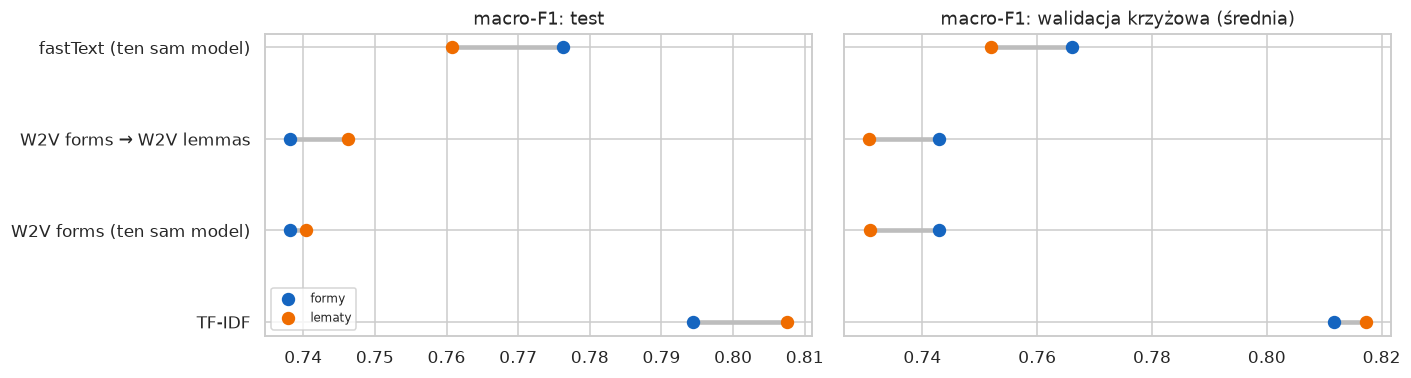

In [16]:
LEM_PAIRS = [  # (porównanie, formy, lematy)
    ("TF-IDF", "TF-IDF | formy", "TF-IDF | lematy"),
    ("W2V forms (ten sam model)", "W2V forms | formy", "W2V forms | lematy"),
    ("W2V forms → W2V lemmas", "W2V forms | formy", "W2V lemmas | lematy"),
    ("fastText (ten sam model)", "fastText | formy", "fastText | lematy"),
]


def vocab_info(name: str) -> str:
    rep, tekst, *_ = EXPS[name]
    if rep == "TF-IDF":
        return f"{TFIDF_DIM[tekst]['cechy (1-2-gramy)']} cech"
    return f"OOV {OOV.loc[name, 'tokeny OOV [%]']:.1f}%"


LEM = pd.DataFrame(
    [
        {
            "porównanie": p,
            "słownik/OOV: formy": vocab_info(a),
            "słownik/OOV: lematy": vocab_info(b),
            "macro-F1 formy": RESULTS.loc[a, "macro-F1"],
            "macro-F1 lematy": RESULTS.loc[b, "macro-F1"],
            "Δ test": RESULTS.loc[b, "macro-F1"] - RESULTS.loc[a, "macro-F1"],
            "CV formy": RESULTS.loc[a, "CV macro-F1"],
            "CV lematy": RESULTS.loc[b, "CV macro-F1"],
            "Δ CV": RESULTS.loc[b, "CV macro-F1"] - RESULTS.loc[a, "CV macro-F1"],
        }
        for p, a, b in LEM_PAIRS
    ]
).set_index("porównanie")
display(LEM.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, (fa, fb, title) in zip(
    axes,
    [("macro-F1 formy", "macro-F1 lematy", "test"), ("CV formy", "CV lematy", "walidacja krzyżowa (średnia)")],
):
    yy = np.arange(len(LEM))
    ax.hlines(yy, LEM[fa], LEM[fb], color="#bdbdbd", lw=3)
    ax.scatter(LEM[fa], yy, color="#1565c0", s=60, label="formy", zorder=3)
    ax.scatter(LEM[fb], yy, color="#ef6c00", s=60, label="lematy", zorder=3)
    ax.set_yticks(yy, LEM.index)
    ax.invert_yaxis()
    ax.set_title(f"macro-F1: {title}")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

# 6. Analiza błędów

## 6.1 Jakie pomyłki popełnia najlepszy model

In [17]:
BEST = MODELS_MAIN[0]
pred = RUNS[BEST]["pred"]
print(f"Najlepszy model (macro-F1 na test): {BEST}")
conf = (
    pd.crosstab(y_test, pred, rownames=["gold"], colnames=["predykcja"])
    .stack()
    .rename("n")
    .reset_index()
)
conf = conf[conf["gold"] != conf["predykcja"]].sort_values("n", ascending=False)
conf["udział błędów [%]"] = (100 * conf["n"] / conf["n"].sum()).round(1)
display(conf.head(8))

Najlepszy model (macro-F1 na test): mmlw-roberta | formy


,gold,predykcja,n,udział błędów [%]
4,minus_m,amb,42,32.3
1,amb,minus_m,23,17.7
2,amb,plus_m,19,14.6
8,plus_m,amb,17,13.1
6,minus_m,plus_m,9,6.9
9,plus_m,minus_m,7,5.4
14,zero,plus_m,5,3.8
7,minus_m,zero,3,2.3


## 6.2 Błędy wg klasy i długości tekstu

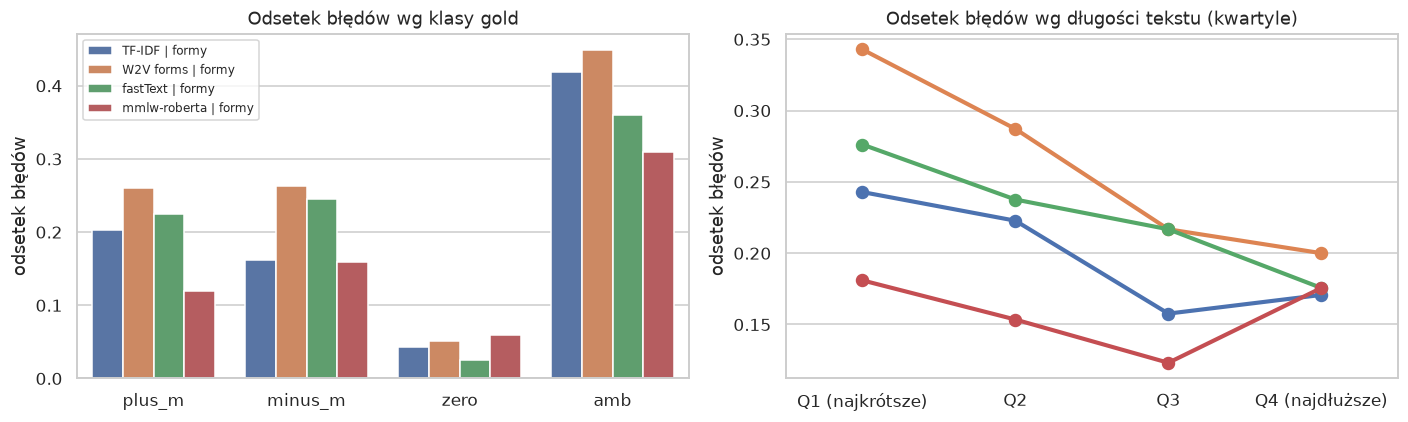

,min,max,count
długość,,,
Q1 (najkrótsze),5,80,210
Q2,81,116,202
Q3,117,157,203
Q4 (najdłuższe),158,455,205


In [18]:
REPS = ["TF-IDF | formy", "W2V forms | formy", "fastText | formy", "mmlw-roberta | formy"]
test["długość"] = pd.qcut(
    test["slowa"], 4, labels=["Q1 (najkrótsze)", "Q2", "Q3", "Q4 (najdłuższe)"]
)
ERRL = pd.concat(
    [
        test[["label", "długość"]].assign(model=m, błąd=RUNS[m]["pred"] != y_test)
        for m in REPS
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=ERRL, x="label", y="błąd", hue="model", order=LABELS, errorbar=None, ax=axes[0])
axes[0].set_title("Odsetek błędów wg klasy gold")
axes[0].set_xlabel("")
sns.pointplot(data=ERRL, x="długość", y="błąd", hue="model", errorbar=None, ax=axes[1])
axes[1].set_title("Odsetek błędów wg długości tekstu (kwartyle)")
axes[1].set_xlabel("")
axes[1].get_legend().remove()
for ax in axes:
    ax.set_ylabel("odsetek błędów")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(test.groupby("długość", observed=True)["slowa"].agg(["min", "max", "count"]))

## 6.3 Czy modele mylą się na tych samych tekstach

Na wykresie: współczynnik Jaccarda zbiorów błędnie sklasyfikowanych tekstów dla każdej pary modeli oraz rozkład liczby modeli, które mylą się na danym tekście.

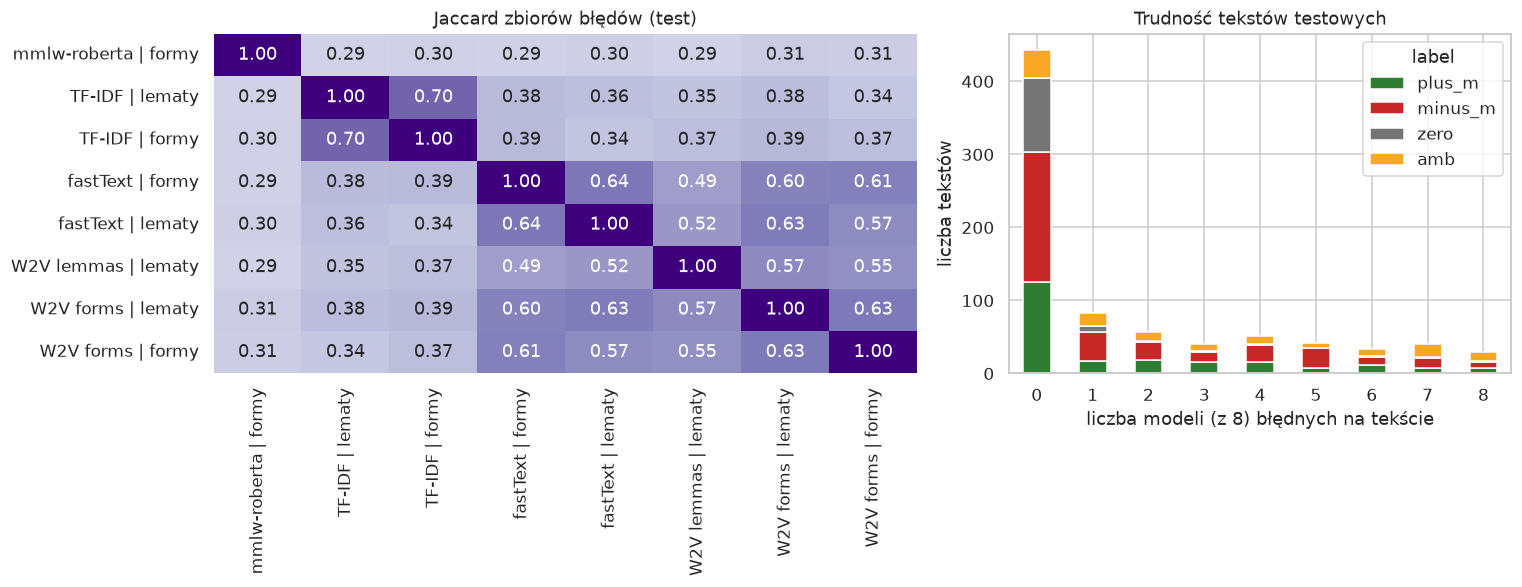

In [19]:
ERR = pd.DataFrame({m: RUNS[m]["pred"] != y_test for m in MODELS_MAIN})
jac = pd.DataFrame(
    [
        [(ERR[a] & ERR[b]).sum() / max((ERR[a] | ERR[b]).sum(), 1) for b in ERR]
        for a in ERR
    ],
    index=ERR.columns,
    columns=ERR.columns,
)
test["ile_modeli_błędnych"] = ERR.sum(axis=1).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, cbar=False, ax=axes[0])
axes[0].set_title("Jaccard zbiorów błędów (test)")
ct = pd.crosstab(test["ile_modeli_błędnych"], test["label"]).reindex(columns=LABELS)
ct.plot.bar(stacked=True, color=[LABEL_COLORS[l] for l in LABELS], ax=axes[1], rot=0)
axes[1].set_xlabel(f"liczba modeli (z {len(MODELS_MAIN)}) błędnych na tekście")
axes[1].set_ylabel("liczba tekstów")
axes[1].set_title("Trudność tekstów testowych")
plt.tight_layout()
plt.show()

## 6.4 Przykłady błędów

Pierwsza tabela: teksty, na których mylą się **wszystkie** modele. Druga: losowe błędy najlepszego modelu wraz z predykcjami pozostałych reprezentacji.

In [20]:
def show(df: pd.DataFrame, cols: list[str], n: int, n_chars: int = 350) -> None:
    d = df.sample(min(n, len(df)), random_state=SEED)[cols].copy()
    d["text"] = d["text"].str[:n_chars] + np.where(d["text"].str.len() > n_chars, " …", "")
    display(d)


for m in REPS:
    test[f"pred {m.split(' | ')[0]}"] = RUNS[m]["pred"]
PRED_COLS = [f"pred {m.split(' | ')[0]}" for m in REPS]

hard = test[test["ile_modeli_błędnych"] == len(MODELS_MAIN)]
print(f"{len(hard)} / {len(test)} tekstów błędnych dla wszystkich modeli; klasy gold:")
display(hard["label"].value_counts().reindex(LABELS).to_frame().T)
show(hard, ["label", *PRED_COLS, "slowa", "text"], 8)

30 / 820 tekstów błędnych dla wszystkich modeli; klasy gold:


label,plus_m,minus_m,zero,amb
count,8,8,1,13


,label,pred TF-IDF,pred W2V forms,pred fastText,pred mmlw-roberta,slowa,text
718,amb,minus_m,plus_m,minus_m,plus_m,76,"Na mnie pierwsze wrażenie zrobił wręcz wspaniałe. Niestety z każdą kolejną wizytą czuję się jakby m była w przychodni NFZ - czekam baaardzo długo (nie wiem po co zapisy na godzinę, skoro i tak przyjmuja jak im sie po..."
434,amb,minus_m,minus_m,minus_m,minus_m,102,"Dostali śmy pokój w którym znajdowały się drzwi do drugiego pokoju, oczywiście zamknięte. Po przyjściu sąsiadów skonkludowali śmy, że słyszymy każde słowo wypowiadane w sąsiednim pokoju. Poprosił em wiec o wymianę po..."
617,minus_m,amb,plus_m,plus_m,plus_m,61,"Lokalizacja super, Krakowski Kazimierz i bliska odległość do starego miasta. Pokoje malutkie bez wentylacji w gorące dni można sie udusić. Towarzystwo mega głośne. Łazienki wspólne i przy tym małe i oblegane, czystoś..."
517,minus_m,amb,amb,amb,amb,62,"Na początku pani doktor nie była zbyt sympatyczna, ale z czasem to się zmieniło. Bardzo negatywne wrażenie wywarło na mnie to, że spóźniła się 15 minut, a nawet nie przeprosiła mnie za to. Co do wywiadu nie mam zastr..."
328,zero,plus_m,plus_m,plus_m,plus_m,102,"witam:) mój maż ma bardzo poważny problem z kregosłupem, ma wypadnie dwa dyski na 4mm i 8 mm, lekarz powiedział ze mąż ma kergosłup 50 latka, a maż ma dopiero 35lat.dwaj lekaże ortopeda i neurochirurg stwierdzaja ope..."
332,amb,minus_m,minus_m,minus_m,minus_m,120,"Pani Sylwio, Ja również jestem pacjentką Pani doktor - ale leczę się prywatnie. Mam PCOS czyli policystyczne jajniki. Pierwsze słyszę, że wielkość biustu ma jakikolwiek związek z tym schorzeniem. Ja mam miseczkę F wi..."
730,plus_m,minus_m,minus_m,minus_m,zero,125,"problem w tym, że ludzie naprawdę chorzy, starsi, nie obsługują komputerow, i nie mogą napisać swojej opinii i pobycie w szpitalu i opiece, jaką otacza ich pani doktor nowak Bo pani doktor nimi sie zajmuje, a nie tym..."
640,minus_m,amb,plus_m,plus_m,plus_m,45,"doktorek Areczek.... baaardzo sie ciesze, ze nie musze na niego patrzec. czlowiek sympatyczny dla osob majacych pojecia o dziwnych sprawach, aczkolwiek dla kogos kto dopiero chce sie nauczyc fizyki - - - niepolecam,:..."


In [21]:
wrong = test[pred != y_test]
show(wrong, ["label", *PRED_COLS, "slowa", "text"], 8)

,label,pred TF-IDF,pred W2V forms,pred fastText,pred mmlw-roberta,slowa,text
394,minus_m,minus_m,minus_m,amb,amb,141,"U Pana Doktora pierwszy raz była m w listopadzie. Po 5 minutowej wizycie zdiagnozowano "" szczelinę odbytu "", otrzymała m receptę na maść i wezwanie na kontrolę za 3 tygodnie. I choć początkowo maść lekko pomogła, to ..."
328,zero,plus_m,plus_m,plus_m,plus_m,102,"witam:) mój maż ma bardzo poważny problem z kregosłupem, ma wypadnie dwa dyski na 4mm i 8 mm, lekarz powiedział ze mąż ma kergosłup 50 latka, a maż ma dopiero 35lat.dwaj lekaże ortopeda i neurochirurg stwierdzaja ope..."
191,plus_m,plus_m,amb,minus_m,minus_m,101,"podzielam zdanie o człowieku legendzie:) polecam z całych sił wyklady super az chce sie chodzic nie zanudza, nie gada niepotrzebnych rzeczy, strasznie konkretny i bezposredni prowadzacy indywidualista w calym zbiorze..."
265,amb,amb,minus_m,amb,minus_m,151,Spędzili śmy w hotelu 3 noce korzystali śmy z pokoju privilege. Wielkim atutem jest lokalizacja na tym niestety plusy dla mnie sie skończyły. Pokoj był duży i czysty jednak widac ze czas sie tu zatrzymał dobrych kilk...
718,amb,minus_m,plus_m,minus_m,plus_m,76,"Na mnie pierwsze wrażenie zrobił wręcz wspaniałe. Niestety z każdą kolejną wizytą czuję się jakby m była w przychodni NFZ - czekam baaardzo długo (nie wiem po co zapisy na godzinę, skoro i tak przyjmuja jak im sie po..."
405,minus_m,plus_m,amb,plus_m,plus_m,289,"Skuszony wieloma bardzo pozytywnymi opiniami postanowił em wybrać Panią Doktor. Z początku był em zadowolony, jednak z czasem miałem coraz większe wątpliwości i w końcu znalazły one wiarygodne potwierdzenie. Zacznijm..."
500,minus_m,minus_m,minus_m,minus_m,amb,131,"Miała m ten robot od pazdziernika 2013 do dzis. Po 3 reklamacji dostalam dzis pieniadze. Wszystko ok. No moze glosny przy pracy, ale spoko, da sie zniesc. Za to wszystko oparte na plastikowych czesciach. U mnie siada..."
664,plus_m,minus_m,minus_m,minus_m,amb,152,"Wizyty bardzo krótkie ale rzeczowo, konkretnie mówi co człowiekowi jest jakie są perspektywy. Jako pierwszy na wizycie refundowanej przez NFZ przyłożył się do babdania, nie olał objawów mimo, iż poprzednik to zrobił...."


## 6.5 Przypadki sporne z anotacji (Część I)

W Części I anotowaliśmy 35 tekstów z `all.text.train`: `sample1` i `sample2` (każdy po 10 tekstów, 3 anotatorów) oraz `sample_<imię>` (po 5 tekstów, 1 anotator). Te teksty leżą w zbiorze treningowym, dlatego porównujemy je z predykcjami **out-of-fold** z walidacji krzyżowej, czyli z modeli, które danego tekstu nie widziały.

Tekst jest **sporny**, jeśli:
- anotatorzy dali różne etykiety (`sample1`, `sample2`), lub
- etykieta anotatora (lub głosowanie większościowe) różni się od gold z korpusu.

In [22]:
ANNOTATORS = ["mikolaj", "dominik", "piotrek"]


def load_sentiments(path: Path, only_ids: set | None = None) -> dict[int, tuple]:
    # uproszczony load_export z agreement.ipynb: tylko etykieta całego tekstu
    out = {}
    for task in json.loads(path.read_text(encoding="utf-8")):
        tid = task["data"]["id"]
        anns = [a for a in task.get("annotations", []) if not a.get("was_cancelled")]
        if (only_ids is not None and tid not in only_ids) or not anns:
            continue
        for res in anns[-1]["result"]:
            if res["from_name"] == "sentiment":
                out[tid] = (res["value"]["choices"][0], task["data"]["text"])
    return out


rows = []
for sample in ["sample1", "sample2"]:
    labs = {a: load_sentiments(ANNOT / sample / f"export_{a}.json") for a in ANNOTATORS}
    for tid in sorted(set.intersection(*(set(d) for d in labs.values()))):
        votes = [labs[a][tid][0] for a in ANNOTATORS]
        top, n = Counter(votes).most_common(1)[0]
        rows.append(
            dict(id=tid, próbka=sample, anotatorzy="/".join(votes),
                 większość=top if n >= 2 else None, tekst_anot=labs[ANNOTATORS[0]][tid][1])
        )
for a in ANNOTATORS:
    folder = f"sample_{a}"
    ids = {t["data"]["id"] for t in json.loads((ANNOT / folder / f"{folder}.json").read_text())}
    for tid, (lab, txt) in load_sentiments(ANNOT / folder / f"export_{a}.json", ids).items():
        rows.append(dict(id=tid, próbka=folder, anotatorzy=lab, większość=lab, tekst_anot=txt))

DIS = pd.DataFrame(rows).set_index("id")
assert (train.loc[DIS.index, "text"] == DIS["tekst_anot"]).all(), "id nie pasuje do train"
DIS["gold"] = y_train[DIS.index]
DIS["niezgodni anotatorzy"] = DIS["anotatorzy"].str.split("/").map(lambda v: len(set(v)) > 1)
DIS["anotacja ≠ gold"] = DIS["większość"] != DIS["gold"]
DIS["sporny"] = DIS["niezgodni anotatorzy"] | DIS["anotacja ≠ gold"]
for m in REPS:
    DIS[f"oof {m.split(' | ')[0]}"] = RUNS[m]["oof"][DIS.index]
OOF_COLS = [f"oof {m.split(' | ')[0]}" for m in REPS]
DIS["modele błędne"] = (DIS[OOF_COLS].to_numpy() != DIS[["gold"]].to_numpy()).sum(axis=1)
DIS["text"] = train.loc[DIS.index, "text"]

print(f"{len(DIS)} tekstów, w tym spornych: {DIS['sporny'].sum()}")
display(DIS[DIS["sporny"]][["próbka", "anotatorzy", "gold", *OOF_COLS, "modele błędne", "text"]]
        .assign(text=lambda d: d["text"].str[:250]))

35 tekstów, w tym spornych: 11


,próbka,anotatorzy,gold,oof TF-IDF,oof W2V forms,oof fastText,oof mmlw-roberta,modele błędne,text
id,,,,,,,,,
611,sample1,plus_m/plus_m/amb,amb,amb,amb,amb,amb,0,"na plus muszę zaliczyć położenie (idealne na nocleg tranzytowy) i śniadanie. Obsługa bardzo miła - na recepcji przywitał nas właściciel, a śniadanie podawała jego żona. Pewnym mankamentem jest brak restauracji w samy..."
1042,sample1,zero/zero/zero,amb,amb,plus_m,plus_m,plus_m,3,Fizyka H 1 (ćwiczenia) - - > dl a por
1199,sample1,minus_m/minus_m/amb,amb,amb,amb,amb,plus_m,1,"Hotel 4 gwiazdkowy zbudowany chyba w latach 90 gdzie pojęcie wysokiej jakości czy luksusu odbiegało od teraźniejszości. Syntetycznie rzecz ujmując. Plusy: czystość, lokalizacja, wygodny materac, siłownia, śniadania. ..."
1468,sample1,minus_m/minus_m/minus_m,amb,minus_m,minus_m,minus_m,minus_m,4,Hotel odbiega standardem od innych hoteli pięciogwiazdkowych. Pokoje wykazują ślady zużycia (wyposażenie z lat bodajże 90 - tych). Obsługa hotelu nie reagowała na uwagi - w apartamencie był wszak telewizor w części w...
2498,sample1,plus_m/amb/amb,amb,amb,amb,amb,amb,0,"Cóż, w tej cenie nie ma co się spodziewać cudów, dźwięk jest, basy praktycznie zerowe co jednak można korektorem w karcie dźwiękowej podbić i wówczas brzmią nawet znośnie, choć jest czysto i w miarę przestrzennie to ..."
5255,sample1,amb/plus_m/plus_m,plus_m,minus_m,amb,minus_m,minus_m,4,"Trochę drogo, ale chyba lepiej wydać więcej pieniędzy, jeśli lekarz ma profesjonalne podejście do pacjenta, a tak jest w przypadku pani doktor. Chodziła m do dwóch innych ginekologów i żadna z pań nie zleciła mi bada..."
5668,sample1,minus_m/minus_m/amb,amb,amb,amb,amb,amb,0,"Pan doktor jest bardzo miły i delikatny przy badaniu, niestety odniosła m wrażenie, że nieco zbyt zapracowany, stąd ocena. Od razu przekazuje nr telefonu i zapewnia, że można dzwonić i pisać o każdej porze, więc w ra..."
1377,sample2,amb/amb/amb,plus_m,amb,amb,amb,plus_m,3,Spędzili śmy dwie noce w starym skrzydle hotelu. Wystrój pokoi jest daleko od współczesnego. To pochodzi od sevenites. Ale były nieskazitelnie czyste. Łazienka odnowiona tylko meble przywróciły wspomnienia dzieciństw...
2548,sample2,amb/amb/plus_m,plus_m,amb,amb,plus_m,amb,3,"ogólnie położenie hotelu super, maly minus że trzeba iść stromo pod górę od ulicy, piękna plaża choć kamienista trochę piachu się też znajdzie. obsługa hotelu miła i pomocna.jedyny minus to łazienki ale wiem że w tą ..."


,sporne (n=11),niesporne (n=24),cały train (OOF) (n=6573)
odsetek błędów [%],,,
TF-IDF,45.5,16.7,19.0
W2V forms,63.6,20.8,26.4
fastText,54.5,16.7,24.1
mmlw-roberta,63.6,8.3,20.4


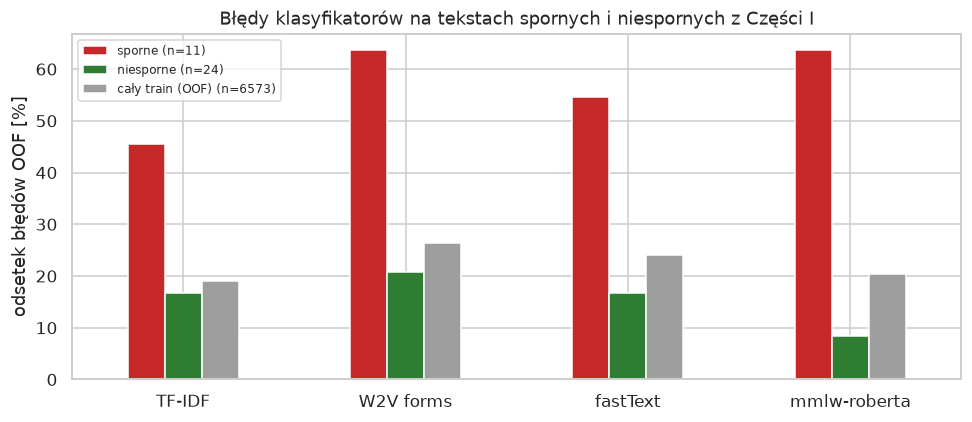

,TF-IDF,W2V forms,fastText,mmlw-roberta
odsetek błędów OOF wg klasy gold [%],,,,
plus_m,20.8,27.5,24.5,17.9
minus_m,13.1,25.0,23.0,17.3
zero,3.7,5.6,4.2,5.6
amb,38.7,43.0,40.5,40.6


In [23]:
SUM = pd.DataFrame(
    {
        **{
            m.split(" | ")[0]: {
                "sporne": (DIS.loc[DIS["sporny"], f"oof {m.split(' | ')[0]}"] != DIS.loc[DIS["sporny"], "gold"]).mean(),
                "niesporne": (DIS.loc[~DIS["sporny"], f"oof {m.split(' | ')[0]}"] != DIS.loc[~DIS["sporny"], "gold"]).mean(),
                "cały train (OOF)": (RUNS[m]["oof"] != y_train).mean(),
            }
            for m in REPS
        }
    }
).T
SUM.columns = [f"{c} (n={n})" for c, n in zip(SUM.columns, [DIS["sporny"].sum(), (~DIS["sporny"]).sum(), len(train)])]
display((SUM * 100).round(1).rename_axis("odsetek błędów [%]"))

ax = (SUM * 100).plot.bar(rot=0, figsize=(9, 4), color=["#c62828", "#2e7d32", "#9e9e9e"])
ax.set_ylabel("odsetek błędów OOF [%]")
ax.set_title("Błędy klasyfikatorów na tekstach spornych i niespornych z Części I")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# błędy klasyfikatora na całym train wg klasy (OOF) - klasy sporne w anotacji vs klasy łatwe
oof_cls = pd.DataFrame(
    {m.split(" | ")[0]: pd.Series(RUNS[m]["oof"] != y_train).groupby(y_train).mean() for m in REPS}
).reindex(LABELS)
display((oof_cls * 100).round(1).rename_axis("odsetek błędów OOF wg klasy gold [%]"))

# 7. Dyskusja

Liczby pochodzą z wykonania notebooka: test = `all.text.test` (820 tekstów), CV = 5-krotna stratyfikowana walidacja krzyżowa na train (6573 teksty). Jeśli dane lub ustawienia się zmienią, trzeba je odświeżyć.

## Podsumowanie: czy zbiór nadaje się do automatycznego przetwarzania?

**Tak.** Każda reprezentacja jest daleko ponad baseline'em (macro-F1 0,15): od 0,74 (Word2Vec) do 0,83 (mmlw-roberta) na teście. Klasa `zero` jest prawie bezbłędna (F1 0,92-0,97), a `plus_m` i `minus_m` są rozpoznawane dobrze (F1 0,74-0,87). Słabym punktem jest **`amb`** (F1 0,49-0,65). W przypadku najlepszego modelu ok. 78% pomyłek dotyczy właśnie tej klasy (`minus_m`→`amb` 32%, `amb`→`minus_m` 18%, `amb`→`plus_m` 15%, `plus_m`→`amb` 13%). To ta sama granica, na której w Części I różnili się anotatorzy, więc trudność wynika z samej definicji klasy, a nie tylko z ograniczeń modeli.

| | test macro-F1 | CV macro-F1 |
|---|---|---|
| mmlw-roberta (formy) | **0,833** | 0,795 ± 0,010 |
| TF-IDF (lematy) | 0,808 | **0,817** ± 0,011 |
| TF-IDF (formy) | 0,794 | 0,812 ± 0,006 |
| fastText (formy) | 0,776 | 0,766 ± 0,010 |
| W2V lemmas (lematy) | 0,746 | 0,731 ± 0,003 |
| W2V forms (formy) | 0,738 | 0,743 ± 0,004 |

## 1. Jak lematyzacja wpływa na rozmiar słownika i skuteczność TF-IDF? Dlaczego w polskim efekt jest silniejszy niż w angielskim?

- **Słownik:** liczba typów spada z 73 200 do 45 894 (−37%), typów występujących co najmniej 2 razy z 33 428 do 20 276 (−39%), a unigramów w TF-IDF z 32 175 do 19 227 (−40%). Liczba wszystkich cech TF-IDF (z bigramami) spada ze 112 896 do 97 790.
- **Skuteczność:** wzrost jest mały i niepewny: +0,013 macro-F1 na teście (95% CI [−0,005; +0,031]) i +0,006 w CV (lematy lepsze w 3 z 5 foldów). Najbardziej zyskuje `amb` (F1 test 0,545 → 0,584, OOF 0,614 → 0,628), czyli klasa, w której ważne są pojedyncze, rzadsze słowa oceniające. Ich formy fleksyjne po lematyzacji sumują się w jedną cechę.
- **Dlaczego w polskim mocniej:** polszczyzna ma bogatą fleksję (7 przypadków, rodzaje, liczby, osoby, aspekt, imiesłowy). W samym korpusie najczęstsze lematy mają po 22-29 różnych form (np. *podać*: 29, *prowadzić*: 28, *dobry*: 25 łącznie z *lepsza*). Bez lematyzacji każda forma to osobna, rzadka cecha, więc przy 6,5 tys. tekstów wagi uczą się na rozproszonych zliczeniach. W angielskim czasownik ma 4-5 form, a przymiotnik zwykle jedną, więc lematyzacja (stemming) zmienia słownik dużo mniej.
- **Dlaczego zysk jest tylko niewielki:** (a) najważniejsze słowa wydźwięku (*polecam*, *nie polecam*, *super*, *brud*) są częste także w pojedynczych formach, a `sublinear_tf`, `min_df=2` i bigramy dobrze je wychwytują; (b) lematyzacja usuwa część informacji (osoba i czas: *polecam* vs *polecali*; stopień: *lepszy* → *dobry*); (c) spaCy wprowadza błędy, np. *pokojach* → *pokoj*, *pokoio*, *urządzć*, *gwiazdeka*, *niemić*.

## 2. Czy lematyzacja pomaga modelom statycznym? Czy fastText jest mniej wrażliwy niż Word2Vec?

- **Nie pomaga.** W CV lematyzacja obniża wynik o ok. 0,012-0,014 we wszystkich wariantach statycznych:
  - W2V forms: formy 0,743 → lematy 0,731;
  - W2V lemmas na lematach: 0,731 (lepszy od W2V forms na formach w 0 z 5 foldów);
  - fastText: 0,766 → 0,752 (1/5 foldów).

  Na teście różnice dla Word2Vec mieszczą się w szumie (+0,002 i +0,008, CI obejmuje 0), a fastText traci 0,016.
- **Dlaczego:** uśrednianie wektorów samo „lematyzuje”, bo formy jednego leksemu mają w modelu bliskie wektory. Lematyzacja nie dodaje więc informacji, za to ją usuwa (osoba, liczba, stopień) i wprowadza dwa źródła szumu:
  - **błędy spaCy:** W2V forms na lematach ma OOV 2,4% zamiast 1,0%. Nowe OOV to zepsute lematy (*pokoio*, *urządzć*, *gwiazdeka*);
  - **niezgodność lematyzacji (pkt 2c):** model `lemmas` IPI PAN był uczony na lematach z innego lematyzatora niż spaCy, więc OOV rośnie do **4,8%**. Najczęstsze OOV to *pokoje* (607), *śniadania* (229), *polecam* (139), *zadbany* (146), *m*/*d* (końcówki aglutynacyjne „był**em**”). Dla tych słów spaCy zwraca formy, których w słowniku lematów IPI PAN nie ma, więc są pomijane. Model uczony na lematach ma sens tylko z tym samym lematyzatorem, którym go uczono.
- **fastText vs Word2Vec:** fastText jest **mniej wrażliwy w sensie pokrycia**:
  - ma OOV 0,5% (głównie liczby i nazwy własne, np. *hualuxe*) wobec 1,0% w Word2Vec, gdzie OOV trafiają też potoczne formy bez polskich znaków (*bedzie*, *musiałem*);
  - nawet dla OOV zwraca wektor z n-gramów znakowych, więc żaden token nie ginie.

  **Wynik spada jednak o tyle samo** (Δ CV −0,014 vs −0,012). N-gramy znakowe już wiążą formy jednego leksemu przez wspólny rdzeń, więc lematyzacja nie ma czego poprawić i zostają tylko jej koszty. Niezależnie od lematyzacji fastText jest wyraźnie lepszy od Word2Vec: +0,038 na teście (CI [+0,015; +0,062]) i +0,023 w CV (5/5 foldów). Wynika to z n-gramów znakowych i większego korpusu KGR10 (3,5 mln słów w słowniku), w tym tekstów internetowych bliższych stylowi opinii.

## 3. Dlaczego lematyzacji zwykle nie stosuje się przy enkoderach transformerowych?

- **Tokenizacja podsłowowa (BPE/SentencePiece)** dzieli słowa na rdzeń i końcówki, więc problem rzadkich form, który lematyzacja rozwiązuje w TF-IDF, tu nie występuje.
- **Model uczono na naturalnym tekście.** Ciąg lematów (*ja być w hotel i on bardzo dobry*) jest niegramatyczny, czyli spoza rozkładu treningowego, więc reprezentacje kontekstowe się psują.
- **Fleksja niesie znaczenie, z którego korzysta mechanizm uwagi:** zgodność składniową (kto co komu), zakres negacji, czas, osobę i stopień przymiotnika. Lematyzacja usuwa dokładnie tę informację, której model kontekstowy używa do odróżniania np. *polecam* od *nie polecali by śmy*.
- Do tego dochodzą błędy lematyzatora (patrz pyt. 1), których model nie może już naprawić.

## 4. Czy prosta reprezentacja TF-IDF jest konkurencyjna wobec enkodera zdań? Z czego to wynika?

**Tak, w praktyce remis.** Na teście mmlw-roberta wygrywa z TF-IDF na lematach o 0,026, ale przedział ufności obejmuje 0 ([−0,002; +0,058]). Istotna jest tylko przewaga nad TF-IDF na formach (+0,039, CI [+0,009; +0,069]). W walidacji krzyżowej jest odwrotnie: TF-IDF (lematy) jest lepszy o 0,023 i wygrywa w 4 z 5 foldów, a na predykcjach out-of-fold z całego train (8× więcej tekstów niż test) przewaga TF-IDF wynika głównie z `amb` (0,628 vs 0,576) i `zero` (0,969 vs 0,937). Sprawdziliśmy, czy przewagi TF-IDF w CV nie tłumaczą prawie-duplikaty w train: teksty z podobieństwem kosinusowym > 0,9 do innego tekstu to 0,1% w train i 0,2% między test a train, czyli nie. Różnica w rankingu wynika więc z wariancji małego testu (tylko 136 tekstów `amb`).

Dlaczego TF-IDF jest tak mocny:
- **Wydźwięk opinii jest silnie leksykalny.** Słowa i bigramy typu *polecam*, *nie polecam*, *brudno*, *strata czasu* są niemal jednoznaczne, a 6,5 tys. tekstów wystarczy, żeby regresja logistyczna nauczyła się ich wag bezpośrednio dla tego zadania.
- **Enkoder jest zamrożony.** mmlw uczono na podobieństwie semantycznym i wyszukiwaniu, więc jego wektor koduje przede wszystkim temat (hotel, lekarz, produkt), a wydźwięk tylko częściowo. Liniowy klasyfikator nie może zmienić tej przestrzeni (to byłby fine-tuning z Zadania 2).
- **Klasa `zero`** to głównie teksty neutralne z innych źródeł (artykuły, opisy medyczne). Różnią się słownictwem, więc TF-IDF rozpoznaje je niemal bezbłędnie (F1 0,97).

Gdzie enkoder ma przewagę:
- lepiej odróżnia `plus_m` od `minus_m` (F1 na teście 0,87/0,87 vs 0,82/0,85);
- mniej myli się na **krótkich tekstach** (Q1: 18% błędów vs 24% dla TF-IDF i 34% dla W2V), gdzie liczy się kontekst i negacja, a nie zliczenia słów;
- popełnia **inne błędy** niż modele leksykalne: Jaccard zbiorów błędów z pozostałymi modelami wynosi ok. 0,3, a między modelami statycznymi 0,5-0,65. Połączenie TF-IDF i enkodera mogłoby więc dać zysk.

Na najdłuższych tekstach (Q4) błąd mmlw rośnie (12% → 18%). Długie opinie częściej mieszają plusy i minusy, a jeden wektor całego tekstu je uśrednia. Obcięcie do 512 tokenów dotyczy tylko 1% tekstów.

Uśrednione wektory statyczne są najsłabsze: średnia rozmywa kilka słów nacechowanych wśród wielu neutralnych i gubi szyk oraz negację (*nie polecam* ≈ *polecam* + *nie*). Dlatego ich błąd silnie zależy od długości (W2V: 34% w Q1 → 20% w Q4).

## 5. Czy przykłady, na których myli się klasyfikator, pokrywają się z przykładami, przy których anotatorzy byli niezgodni?

**Tak, wyraźnie** (na małej próbie: 35 tekstów, w tym 11 spornych). Odsetek błędów out-of-fold na tekstach spornych wynosi 45-64%, a na niespornych 8-21%, czyli 2,7-7,7 razy mniej, zależnie od modelu (średnio w train 19-26%).

Przypadki z tabeli 6.5:
- **Klasyfikator zgadza się z anotatorami, a nie z gold.** Tekst 1468 (hotel pięciogwiazdkowy z listą usterek): trzech anotatorów jednogłośnie dało `minus_m`, gold to `amb`, i wszystkie 4 modele mówią `minus_m`. Podobnie tekst 3892: anotator i 3 z 4 modeli dali `zero` przy gold `plus_m`. Część „błędów” klasyfikatora to więc raczej wątpliwe etykiety gold.
- **Tekst 1042** („Fizyka H 1 (ćwiczenia) - - > dl a por”) to praktycznie pusty fragment z gold `amb`. Anotatorzy dali `zero`, a 3 modele `plus_m`. Takiego tekstu nie da się poprawnie oetykietować.
- **Granica `amb` ↔ wyraźna opinia.** W tekstach 5255, 2705, 1377 i 2548 spór (między anotatorami lub z gold) dotyczy `amb` i myli się na nich 3-4 z 4 modeli.
- **Przypadek odwrotny.** W tekstach 611, 1199, 2498 i 5668 gold to `amb`, a anotatorzy byli podzieleni między `amb` i etykietę biegunową (w 611, 1199 i 5668 większość wybrała etykietę biegunową). Modele (3-4 z 4) wybierają tu `amb` zgodnie z gold. Te opinie jawnie wyliczają plusy i minusy (*na plus muszę zaliczyć…, pewnym mankamentem jest…*), co modele leksykalne łatwo wychwytują.

Zbiorczo: w Części I wszystkie niezgodności anotatorów dotyczyły klasy `amb`, a tutaj `amb` ma najwyższy błąd out-of-fold u wszystkich modeli (39-43% wobec 4-6% dla `zero`) i należy do niej 13 z 30 tekstów testowych, na których mylą się wszystkie modele. Niepewność modeli i ludzi dotyczy tych samych tekstów. Jakość klasyfikacji ogranicza tu w dużej mierze spójność samej anotacji klasy `amb`, a nie tylko reprezentacja tekstu.